# CSE 436: Data Mining Lab
## Lab Report: Comparison Analysis of Apriori and FP-Growth Algorithms

**Name:** Md. Reahoon Zannah  
**Student ID:** 223002038  
**Dataset:** Market Basket Analysis (`Market_Basket_Analysis.csv`)

---

### Given parameters
- **Minimum support:** 0.003
- **Minimum confidence:** 0.2



## 1. Importing Libraries

In [ ]:
import time
import math
from collections import Counter, defaultdict
from itertools import combinations

import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

## 2. Parameters and Dataset Loading

In [ ]:
DATA_PATH      = "Market_Basket_Analysis.csv"   # keep the CSV in the same folder as this notebook
MIN_SUPPORT    = 0.003
MIN_CONFIDENCE = 0.2

The CSV has **no header row**: every row is one transaction and the empty cells (`NaN`) are only padding. So we load with `header=None`; otherwise the first transaction would be lost as a header.

In [ ]:
df_raw = pd.read_csv(DATA_PATH, header=None)
print("Raw shape (rows x columns):", df_raw.shape)
df_raw.head()

Raw shape (rows x columns): (7501, 20)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Preprocessing: Building the Transaction Database

In [ ]:
# Remove NaN padding, strip spaces, convert to lower case, remove duplicates inside a basket
transactions = []
for row in df_raw.values:
    basket = {str(item).strip().lower() for item in row if pd.notna(item) and str(item).strip() != ""}
    if basket:
        transactions.append(tuple(sorted(basket)))   # sorted tuple -> fixed item order

N = len(transactions)
all_items = sorted({i for t in transactions for i in t})
lengths = [len(t) for t in transactions]

print("Number of transactions :", N)
print("Number of unique items :", len(all_items))
print("Average basket size    : %.2f" % (sum(lengths) / N))
print("Smallest / Largest     :", min(lengths), "/", max(lengths))

MIN_SUP_COUNT = math.ceil(MIN_SUPPORT * N)
print("\nMinimum support = %s  ->  minimum support count = %d" % (MIN_SUPPORT, MIN_SUP_COUNT))

Number of transactions : 7501
Number of unique items : 119
Average basket size    : 3.91
Smallest / Largest     : 1 / 20

Minimum support = 0.003  ->  minimum support count = 23


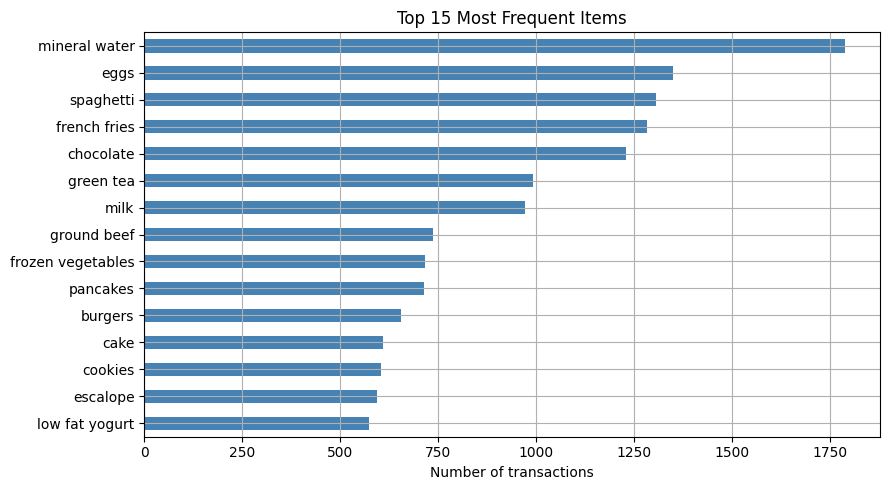

In [ ]:
# Item popularity (top 15)
item_freq = Counter(i for t in transactions for i in t)
top = pd.Series(item_freq).sort_values(ascending=False).head(15)

ax = top[::-1].plot(kind="barh", color="steelblue")
ax.set_title("Top 15 Most Frequent Items")
ax.set_xlabel("Number of transactions")
plt.tight_layout()
plt.show()

## 4. Apriori Algorithm

**Idea:** level-wise search. Frequent $(k-1)$-itemsets $L_{k-1}$ are joined to create candidates $C_k$; any candidate with an infrequent subset is **pruned** (Apriori property); the database is scanned to count the support of the remaining candidates, giving $L_k$.

In [ ]:
def apriori(transactions, min_sup_count, verbose=False):
    """Apriori frequent itemset mining.
    Returns: (frequent_itemsets {itemset: support_count}, total_candidates)"""
    frequent = {}
    total_candidates = 0

    # ---- Level 1: scan the database once ----
    c1 = Counter(i for t in transactions for i in t)
    total_candidates += len(c1)
    L = {(i,): c for i, c in c1.items() if c >= min_sup_count}
    frequent.update(L)
    if verbose:
        print("C1: %d candidates -> L1: %d frequent 1-itemsets" % (len(c1), len(L)))

    k = 2
    while L:
        prev = sorted(L)                      # sorted (k-1)-itemsets
        prev_set = set(prev)

        # ---- Join step: merge itemsets that share the first k-2 items ----
        c_before = []
        for a in range(len(prev)):
            for b in range(a + 1, len(prev)):
                if prev[a][:-1] == prev[b][:-1]:
                    c_before.append(prev[a] + (prev[b][-1],))
                else:
                    break

        # ---- Prune step: every (k-1)-subset must be frequent ----
        c_after = [c for c in c_before
                   if all(s in prev_set for s in combinations(c, k - 1))]
        total_candidates += len(c_after)

        if verbose:
            print("C%d(before pruning): %d | C%d(after pruning): %d"
                  % (k, len(c_before), k, len(c_after)), end=" | ")

        if not c_after:
            if verbose: print("L%d: 0" % k)
            break

        # ---- Scan database: count support of the surviving candidates ----
        cand_set = set(c_after)
        usable = {i for itemset in prev for i in itemset}
        counts = defaultdict(int)
        for t in transactions:
            t_use = [i for i in t if i in usable]
            if len(t_use) < k:
                continue
            for comb in combinations(t_use, k):
                if comb in cand_set:
                    counts[comb] += 1

        L = {c: n for c, n in counts.items() if n >= min_sup_count}
        frequent.update(L)
        if verbose:
            print("L%d: %d frequent %d-itemsets" % (k, len(L), k))
            for itemset, n in sorted(L.items(), key=lambda x: -x[1])[:3]:
                print("      e.g.", list(itemset), "sup:", n)
        k += 1

    return frequent, total_candidates

In [ ]:
print("Minimum support threshold (count):", MIN_SUP_COUNT, "\n")
t0 = time.perf_counter()
apriori_result, apriori_cands = apriori(transactions, MIN_SUP_COUNT, verbose=True)
apriori_time = time.perf_counter() - t0

print("\nTotal frequent itemsets :", len(apriori_result))
print("Total candidates        :", apriori_cands)
print("Time executed (incl. printing): %.4f s" % apriori_time)

Minimum support threshold (count): 23 

C1: 119 candidates -> L1: 115 frequent 1-itemsets
C2(before pruning): 6555 | C2(after pruning): 6555 | L2: 786 frequent 2-itemsets
      e.g. ['mineral water', 'spaghetti'] sup: 448
      e.g. ['chocolate', 'mineral water'] sup: 395
      e.g. ['eggs', 'mineral water'] sup: 382
C3(before pruning): 9023 | C3(after pruning): 5304 | L3: 504 frequent 3-itemsets
      e.g. ['ground beef', 'mineral water', 'spaghetti'] sup: 128
      e.g. ['chocolate', 'mineral water', 'spaghetti'] sup: 119
      e.g. ['milk', 'mineral water', 'spaghetti'] sup: 118
C4(before pruning): 1035 | C4(after pruning): 511 | L4: 38 frequent 4-itemsets
      e.g. ['chocolate', 'milk', 'mineral water', 'spaghetti'] sup: 37
      e.g. ['frozen vegetables', 'milk', 'mineral water', 'spaghetti'] sup: 34
      e.g. ['chocolate', 'eggs', 'mineral water', 'spaghetti'] sup: 34
C5(before pruning): 8 | C5(after pruning): 4 | L5: 0 frequent 5-itemsets

Total frequent itemsets : 1443
Total 

## 5. FP-Growth Algorithm

**Idea:** no candidate generation. The database is scanned twice: first to find frequent items, then to compress all transactions into an **FP-tree** (items sorted by descending frequency so that common prefixes are shared). Frequent patterns are mined recursively from the **conditional pattern base** and **conditional FP-tree** of each item.

In [ ]:
class FPNode:
    __slots__ = ("item", "count", "parent", "children")
    def __init__(self, item, count, parent):
        self.item = item
        self.count = count
        self.parent = parent
        self.children = {}


def build_fp_tree(weighted_transactions, min_sup_count):
    """Build an FP-tree from (items, count) pairs.
    Returns: (header_table {item: [nodes]}, item_counts of frequent items)"""
    # Scan 1: item supports
    item_counts = defaultdict(int)
    for items, cnt in weighted_transactions:
        for i in items:
            item_counts[i] += cnt
    item_counts = {i: c for i, c in item_counts.items() if c >= min_sup_count}

    # Scan 2: insert transactions with items ordered by descending support
    root = FPNode(None, 0, None)
    header = defaultdict(list)                 # node-links of each item
    for items, cnt in weighted_transactions:
        ordered = sorted((i for i in items if i in item_counts),
                         key=lambda i: (-item_counts[i], i))
        node = root
        for i in ordered:
            child = node.children.get(i)
            if child is None:
                child = FPNode(i, 0, node)
                node.children[i] = child
                header[i].append(child)
            child.count += cnt
            node = child
    return header, item_counts


def fp_mine(header, item_counts, min_sup_count, suffix, result):
    """Recursively mine frequent patterns (FP-Growth(Tree, alpha))."""
    # process items from least frequent to most frequent
    for item in sorted(item_counts, key=lambda i: (item_counts[i], i)):
        pattern = suffix + (item,)
        result[tuple(sorted(pattern))] = item_counts[item]

        # conditional pattern base: prefix path of every node of `item`
        cond_base = []
        for node in header[item]:
            path, p = [], node.parent
            while p.item is not None:
                path.append(p.item)
                p = p.parent
            if path:
                cond_base.append((path[::-1], node.count))

        if cond_base:
            cond_header, cond_counts = build_fp_tree(cond_base, min_sup_count)
            if cond_counts:
                fp_mine(cond_header, cond_counts, min_sup_count, pattern, result)


def fp_growth(transactions, min_sup_count):
    """FP-Growth frequent itemset mining. Returns {itemset: support_count}"""
    header, item_counts = build_fp_tree([(t, 1) for t in transactions], min_sup_count)
    result = {}
    fp_mine(header, item_counts, min_sup_count, (), result)
    return result

In [ ]:
t0 = time.perf_counter()
fp_result = fp_growth(transactions, MIN_SUP_COUNT)
fp_time = time.perf_counter() - t0

print("Total frequent itemsets :", len(fp_result))
print("Time executed           : %.4f s" % fp_time)

# Both algorithms must return exactly the same patterns and support counts
assert apriori_result == fp_result, "Mismatch between Apriori and FP-Growth results!"
print("\nVerification: Apriori and FP-Growth produced IDENTICAL frequent itemsets.")

Total frequent itemsets : 1443
Time executed           : 0.1376 s

Verification: Apriori and FP-Growth produced IDENTICAL frequent itemsets.


### 5.1 Frequent itemsets by length

In [ ]:
by_len = Counter(len(s) for s in fp_result)
summary = pd.DataFrame({"Itemset length": sorted(by_len),
                        "Number of frequent itemsets": [by_len[k] for k in sorted(by_len)]})
display(summary)

# Top frequent itemsets with 2 or more items
rows = [{"Itemset": ", ".join(s), "Length": len(s), "Support count": c, "Support": round(c / N, 4)}
        for s, c in fp_result.items() if len(s) >= 2]
top_itemsets = pd.DataFrame(rows).sort_values("Support count", ascending=False).head(15).reset_index(drop=True)
top_itemsets

,Itemset length,Number of frequent itemsets
0,1,115
1,2,786
2,3,504
3,4,38


,Itemset,Length,Support count,Support
0,"mineral water, spaghetti",2,448,0.0597
1,"chocolate, mineral water",2,395,0.0527
2,"eggs, mineral water",2,382,0.0509
3,"milk, mineral water",2,360,0.0480
4,"ground beef, mineral water",2,307,0.0409
5,"chocolate, spaghetti",2,294,0.0392
6,"ground beef, spaghetti",2,294,0.0392
7,"eggs, spaghetti",2,274,0.0365
8,"eggs, french fries",2,273,0.0364
9,"frozen vegetables, mineral water",2,268,0.0357


## 6. Association Rule Generation

For every frequent itemset $I$ and every non-empty proper subset $A \subset I$, the rule $A \Rightarrow (I - A)$ is kept if

$$\text{confidence}(A \Rightarrow B) = \frac{\text{sup}(A \cup B)}{\text{sup}(A)} \ge \text{min\_conf}$$

Lift is also reported: $\text{lift} = \dfrac{\text{confidence}}{\text{sup}(B)}$.

In [ ]:
def generate_rules(freq_itemsets, n_transactions, min_conf):
    rules = []
    for itemset, cnt in freq_itemsets.items():
        if len(itemset) < 2:
            continue
        for r in range(1, len(itemset)):
            for ante in combinations(itemset, r):
                cons = tuple(i for i in itemset if i not in ante)
                conf = cnt / freq_itemsets[ante]
                if conf >= min_conf:
                    lift = conf / (freq_itemsets[cons] / n_transactions)
                    rules.append({
                        "Antecedent": ", ".join(ante),
                        "Consequent": ", ".join(cons),
                        "Support": cnt / n_transactions,
                        "Confidence": conf,
                        "Lift": lift,
                    })
    return pd.DataFrame(rules)

rules_df = generate_rules(fp_result, N, MIN_CONFIDENCE)
rules_df = rules_df.sort_values(["Lift", "Confidence"], ascending=False).reset_index(drop=True)

print("Minimum support = %s, Minimum confidence = %s" % (MIN_SUPPORT, MIN_CONFIDENCE))
print("Total association rules generated:", len(rules_df))
rules_df.head(15).round(4)

Minimum support = 0.003, Minimum confidence = 0.2
Total association rules generated: 1364


,Antecedent,Consequent,Support,Confidence,Lift
0,"frozen vegetables, soup","milk, mineral water",0.0031,0.3833,7.9872
1,"frozen vegetables, olive oil","milk, mineral water",0.0033,0.2941,6.1283
2,"mineral water, whole wheat pasta",olive oil,0.0039,0.4028,6.1159
3,"milk, soup","frozen vegetables, mineral water",0.0031,0.2018,5.6469
4,tomato sauce,"ground beef, spaghetti",0.0031,0.2170,5.5360
5,"frozen vegetables, milk, mineral water",soup,0.0031,0.2771,5.4844
6,fromage blanc,honey,0.0033,0.2451,5.1643
7,"spaghetti, tomato sauce",ground beef,0.0031,0.4894,4.9806
8,light cream,chicken,0.0045,0.2906,4.8440
9,pasta,escalope,0.0059,0.3729,4.7008


Rules with Lift > 1 (positive association): 1355
Rules with confidence >= 0.5            : 83


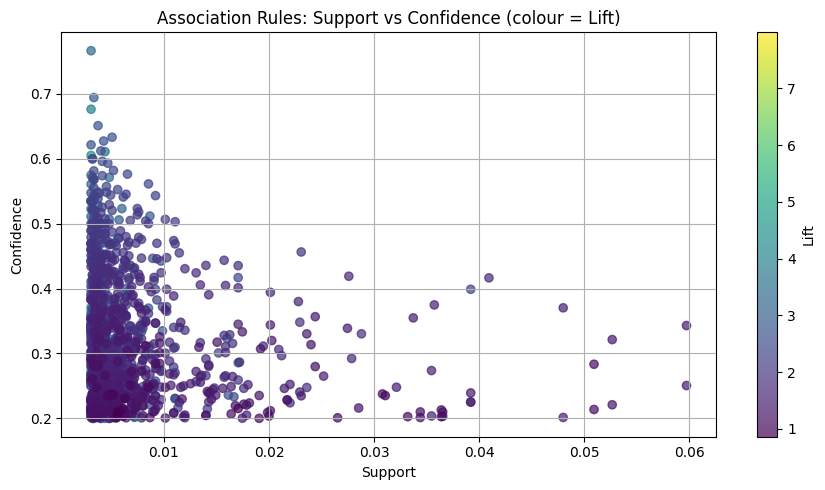

In [ ]:
print("Rules with Lift > 1 (positive association):", (rules_df["Lift"] > 1).sum())
print("Rules with confidence >= 0.5            :", (rules_df["Confidence"] >= 0.5).sum())

plt.scatter(rules_df["Support"], rules_df["Confidence"], c=rules_df["Lift"], cmap="viridis", alpha=0.7)
plt.colorbar(label="Lift")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Association Rules: Support vs Confidence (colour = Lift)")
plt.tight_layout()
plt.show()

## 7. Comparative Analysis: Apriori vs FP-Growth

Following the lab exercise, both algorithms are run on the **same dataset** with the **same minimum support** and compared using **line charts of execution time only**. Five minimum support thresholds are used: the given value **0.003** and four other values. Every run is repeated 3 times and the **average** time is reported. No printing is done inside the timed region.

In [ ]:
THRESHOLDS = [0.003, 0.005, 0.01, 0.02, 0.03]
REPEATS = 3

def avg_time(func, *args):
    times = []
    for _ in range(REPEATS):
        t0 = time.perf_counter()
        out = func(*args)
        times.append(time.perf_counter() - t0)
    return sum(times) / len(times), out

records = []
for s in THRESHOLDS:
    cnt = math.ceil(s * N)
    t_ap, (ap_out, ap_cands) = avg_time(apriori, transactions, cnt)
    t_fp, fp_out = avg_time(fp_growth, transactions, cnt)
    assert ap_out == fp_out
    records.append({
        "Min support": s,
        "Min count": cnt,
        "Frequent itemsets": len(fp_out),
        "Apriori candidates": ap_cands,
        "Apriori time (s)": t_ap,
        "FP-Growth time (s)": t_fp,
    })
    print("support=%.3f  Apriori=%.4fs  FP-Growth=%.4fs  itemsets=%d" % (s, t_ap, t_fp, len(fp_out)))

results = pd.DataFrame(records)
results["Speedup (Apriori / FP-Growth)"] = results["Apriori time (s)"] / results["FP-Growth time (s)"]
results.round(4)

support=0.003  Apriori=0.1290s  FP-Growth=0.1682s  itemsets=1443
support=0.005  Apriori=0.0894s  FP-Growth=0.1436s  itemsets=725
support=0.010  Apriori=0.0572s  FP-Growth=0.0776s  itemsets=257
support=0.020  Apriori=0.0367s  FP-Growth=0.0540s  itemsets=103
support=0.030  Apriori=0.0269s  FP-Growth=0.0959s  itemsets=54


,Min support,Min count,Frequent itemsets,Apriori candidates,Apriori time (s),FP-Growth time (s),Speedup (Apriori / FP-Growth)
0,0.003,23,1443,12493,0.1290,0.1682,0.7671
1,0.005,38,725,7505,0.0894,0.1436,0.6228
2,0.010,76,257,3373,0.0572,0.0776,0.7372
3,0.020,151,103,1558,0.0367,0.0540,0.6785
4,0.030,226,54,763,0.0269,0.0959,0.2807


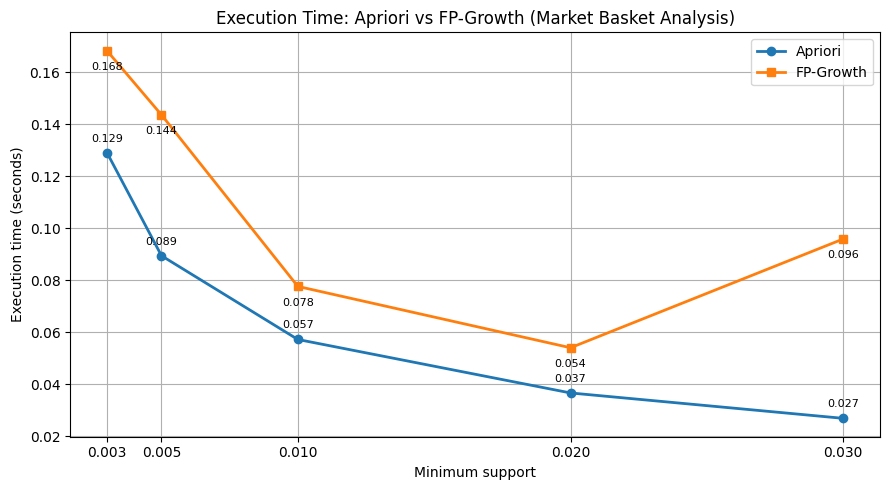

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(results["Min support"], results["Apriori time (s)"], marker="o", linewidth=2, label="Apriori")
plt.plot(results["Min support"], results["FP-Growth time (s)"], marker="s", linewidth=2, label="FP-Growth")

for _, r in results.iterrows():
    plt.annotate("%.3f" % r["Apriori time (s)"], (r["Min support"], r["Apriori time (s)"]),
                 textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
    plt.annotate("%.3f" % r["FP-Growth time (s)"], (r["Min support"], r["FP-Growth time (s)"]),
                 textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8)

plt.xticks(results["Min support"])
plt.xlabel("Minimum support")
plt.ylabel("Execution time (seconds)")
plt.title("Execution Time: Apriori vs FP-Growth (Market Basket Analysis)")
plt.legend()
plt.tight_layout()
plt.show()

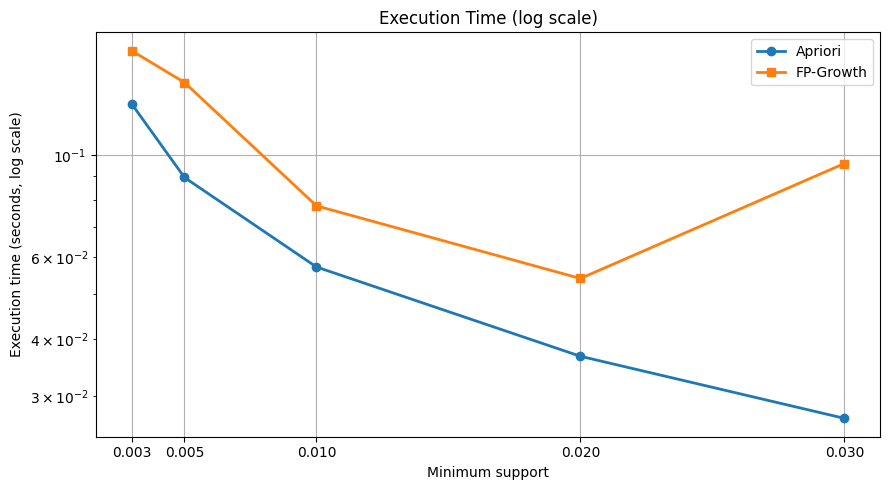

In [ ]:
# Same comparison on a log scale (helps when one curve is much larger than the other)
plt.figure(figsize=(9, 5))
plt.plot(results["Min support"], results["Apriori time (s)"], marker="o", linewidth=2, label="Apriori")
plt.plot(results["Min support"], results["FP-Growth time (s)"], marker="s", linewidth=2, label="FP-Growth")
plt.yscale("log")
plt.xticks(results["Min support"])
plt.xlabel("Minimum support")
plt.ylabel("Execution time (seconds, log scale)")
plt.title("Execution Time (log scale)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Automatic summary of the measured results
fast = results.loc[results["Speedup (Apriori / FP-Growth)"].idxmax()]
print("Time at the given support (0.003): Apriori = %.4f s, FP-Growth = %.4f s"
      % (results.iloc[0]["Apriori time (s)"], results.iloc[0]["FP-Growth time (s)"]))
for _, r in results.iterrows():
    faster = "FP-Growth" if r["FP-Growth time (s)"] < r["Apriori time (s)"] else "Apriori"
    ratio = max(r["Apriori time (s)"], r["FP-Growth time (s)"]) / min(r["Apriori time (s)"], r["FP-Growth time (s)"])
    print("support %.3f -> faster: %-9s (%.2fx)" % (r["Min support"], faster, ratio))

Time at the given support (0.003): Apriori = 0.1290 s, FP-Growth = 0.1682 s
support 0.003 -> faster: Apriori   (1.30x)
support 0.005 -> faster: Apriori   (1.61x)
support 0.010 -> faster: Apriori   (1.36x)
support 0.020 -> faster: Apriori   (1.47x)
support 0.030 -> faster: Apriori   (3.56x)
